# Tutorial · Build our six-model forecast ensemble

Run the cells from top to bottom with **Shift + Enter** and compare your output with each ✅ checkpoint. Scores are printed for day 1, day 2, day 3 and their mean. The notebook is saved with outputs, so you can also read along. Stuck? See slide 10 or *Troubleshooting* in the README, or raise your hand.

## Step 0 · Setup check

In [1]:
import sys
sys.path.insert(0, "..")            # sst_models.py lives one folder up
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sst_models import load_checkpoint, predict, score, rmse_per_day

ckpts = sorted(Path("../checkpoints").glob("*.pt"))
print(f"torch {torch.__version__}, {len(ckpts)} checkpoints found")
assert len(ckpts) == 6, "Checkpoints not found: open this notebook from the notebooks/ folder"
print("Setup OK")

torch 2.2.2, 6 checkpoints found
Setup OK


In [2]:
# Plot settings (nothing to change here)
BLUE, ORANGE, NAVY, GREY = "#1F6F9F", "#C55A23", "#12263A", "#8A94A3"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)

✅ **Checkpoint 0:** `torch 2.2.2, 6 checkpoints found` and `Setup OK`. Another torch 2.x version is fine.

## Step 1 · Load the data and score the baseline

In [3]:
with np.load("../data/validation.npz") as data:
    X, y = data["X"], data["y"]
    mask = data["mask"].astype(bool)
    dates = data["dates"].astype(str)
    lat, lon = data["lat"], data["lon"]

print("X:", X.shape)    # (examples, 14 input days, lat, lon)
print("y:", y.shape)    # (examples, 3 forecast days, lat, lon)
print("ocean cells:", mask.sum(), "of", mask.size)

X: (728, 14, 12, 14)
y: (728, 3, 12, 14)
ocean cells: 143 of 168


✅ **Checkpoint 1a:** `X: (728, 14, 12, 14)`, `y: (728, 3, 12, 14)`, `ocean cells: 143 of 168`.

In [5]:
def report(name, p):
    """RMSE for each forecast day, then their mean (the competition score)."""
    d = rmse_per_day(p, y, mask)
    print(f"{name:<24} day 1 {d[0]:.4f} | day 2 {d[1]:.4f} | day 3 {d[2]:.4f} | mean {d.mean():.4f}")

# copy the last day 3 times
persistence = np.repeat(X[:, -1:], 3, axis=1)
report("persistence", persistence)  # day 1, 2, 3 + mean

persistence              day 1 0.1792 | day 2 0.3171 | day 3 0.4262 | mean 0.3075


✅ **Checkpoint 1b:** `persistence  day 1 0.1792 | day 2 0.3171 | day 3 0.4262 | mean 0.3075`.

## Step 2 · Run the six trained networks

Takes about 30 seconds on a laptop CPU.

In [6]:
FAMILIES = ["tcn", "spatial_tcn"]
SEEDS = [444, 445, 446]

preds = {}
for family in FAMILIES:          # tcn, spatial_tcn
    for seed in SEEDS:           # 444, 445, 446
        path = f"../checkpoints/{family}_seed{seed}.pt"
        _, model = load_checkpoint(path)
        preds[(family, seed)] = predict(model, X)

In [7]:
print("shape of each forecast:", preds[("tcn", 444)].shape)
for (family, seed), p in preds.items():
    report(f"{family}, seed {seed}", p)

shape of each forecast: (728, 3, 12, 14)
tcn, seed 444            day 1 0.1546 | day 2 0.2873 | day 3 0.3943 | mean 0.2788
tcn, seed 445            day 1 0.1550 | day 2 0.2869 | day 3 0.3924 | mean 0.2781
tcn, seed 446            day 1 0.1567 | day 2 0.2851 | day 3 0.3872 | mean 0.2763
spatial_tcn, seed 444    day 1 0.1566 | day 2 0.2896 | day 3 0.3952 | mean 0.2805
spatial_tcn, seed 445    day 1 0.1530 | day 2 0.2888 | day 3 0.3965 | mean 0.2794
spatial_tcn, seed 446    day 1 0.1495 | day 2 0.2836 | day 3 0.3911 | mean 0.2747


✅ **Checkpoint 2:** `shape of each forecast: (728, 3, 12, 14)`, then six lines with a mean between `0.2747` and `0.2805`.

Each architecture, averaged over its 3 runs:

In [ ]:
# Averages the RMSE scores.

def row(name, p):
    d = rmse_per_day(p, y, mask)
    return {"model": name, "day 1": d[0], "day 2": d[1], "day 3": d[2], "mean RMSE": d.mean()}

singles = pd.DataFrame([row(f"{f}, seed {s}", p) for (f, s), p in preds.items()])
singles["architecture"] = [f for f, _ in preds]
singles.groupby("architecture")[["day 1", "day 2", "day 3", "mean RMSE"]].mean()

,day 1,day 2,day 3,mean RMSE
architecture,,,,
spatial_tcn,0.1530,0.2873,0.3943,0.2782
tcn,0.1554,0.2865,0.3913,0.2777


## Step 3 · Deep ensemble: average the seeds

In [ ]:
# Averages the predictions before calculating RMSE.
family_mean = {
    f: np.mean([preds[(f, s)] for s in SEEDS], axis=0)
    for f in FAMILIES
}
for f in FAMILIES:
    report(f"{f} × 3 seeds", family_mean[f])

tcn × 3 seeds            day 1 0.1522 | day 2 0.2824 | day 3 0.3868 | mean 0.2738
spatial_tcn × 3 seeds    day 1 0.1497 | day 2 0.2835 | day 3 0.3899 | mean 0.2743


✅ **Checkpoint 3:** `tcn × 3 seeds  day 1 0.1522 | day 2 0.2824 | day 3 0.3868 | mean 0.2738` and `spatial_tcn × 3 seeds  day 1 0.1497 | day 2 0.2835 | day 3 0.3899 | mean 0.2743`.

## Step 4 · Averaging: combine the two architectures

In [10]:
ensemble = np.mean([family_mean[f] for f in FAMILIES], axis=0)
report("all six, 50/50", ensemble)

all six, 50/50           day 1 0.1474 | day 2 0.2770 | day 3 0.3811 | mean 0.2685


✅ **Checkpoint 4:** `all six, 50/50  day 1 0.1474 | day 2 0.2770 | day 3 0.3811 | mean 0.2685`.

In [11]:
steps = pd.DataFrame([
    row("persistence", persistence),
    {**row("single model (average over 6 runs)", ensemble), **singles[["day 1", "day 2", "day 3", "mean RMSE"]].mean().to_dict()},
    row("best single run (spatial, seed 446)", preds[("spatial_tcn", 446)]),
    row("flattened TCN × 3 seeds", family_mean["tcn"]),
    row("spatial TCN × 3 seeds", family_mean["spatial_tcn"]),
    row("all six, 50/50", ensemble),
]).set_index("model")
steps

,day 1,day 2,day 3,mean RMSE
model,,,,
persistence,0.1792,0.3171,0.4262,0.3075
single model (average over 6 runs),0.1542,0.2869,0.3928,0.2780
"best single run (spatial, seed 446)",0.1495,0.2836,0.3911,0.2747
flattened TCN × 3 seeds,0.1522,0.2824,0.3868,0.2738
spatial TCN × 3 seeds,0.1497,0.2835,0.3899,0.2743
"all six, 50/50",0.1474,0.2770,0.3811,0.2685


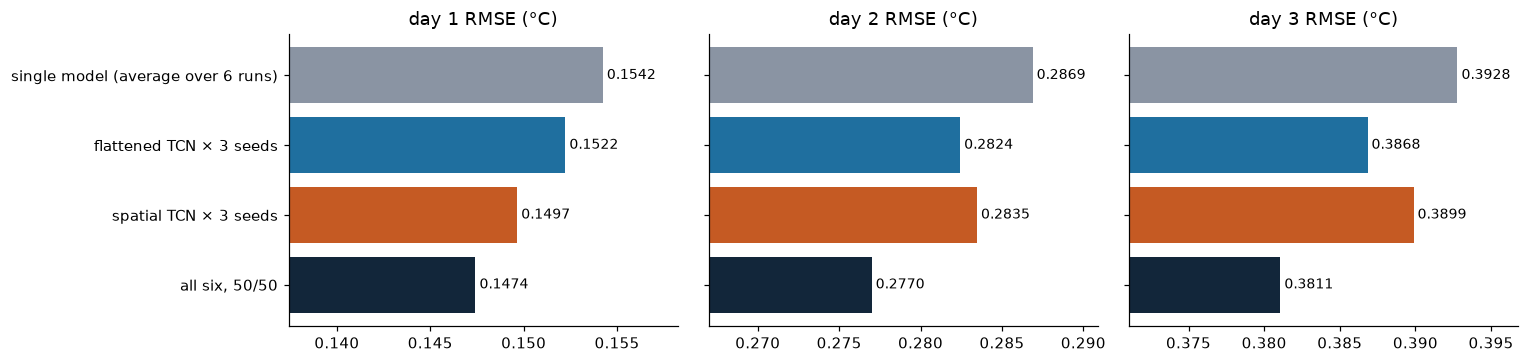

In [12]:
show_rows = ["single model (average over 6 runs)", "flattened TCN × 3 seeds", "spatial TCN × 3 seeds", "all six, 50/50"]
colors = [GREY, BLUE, ORANGE, NAVY]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, day in zip(axes, ["day 1", "day 2", "day 3"]):
    vals = steps.loc[show_rows, day]
    ax.barh(range(4), vals, color=colors)
    ax.set_yticks(range(4), show_rows if day == "day 1" else [""] * 4)
    ax.set_xlim(vals.min() - .01, vals.max() + .004); ax.invert_yaxis()
    for k, v in enumerate(vals):
        ax.text(v, k, f" {v:.4f}", va="center", fontsize=9)
    ax.set_title(f"{day} RMSE (°C)")
plt.tight_layout(); plt.show()

## Step 5 · Why mixing architectures wins: error correlation

In [13]:
keys = list(preds)
errors = np.array([(preds[k] - y)[:, :, mask].ravel()
                   for k in keys])      # (6, all errors)
corr = np.corrcoef(errors)              # (6, 6)

In [14]:
# average ρ over same- and cross-architecture pairs
same = [corr[a, b] for a in range(6) for b in range(a + 1, 6) if keys[a][0] == keys[b][0]]
cross = [corr[a, b] for a in range(6) for b in range(a + 1, 6) if keys[a][0] != keys[b][0]]
print(f"ρ, same architecture, different seed: {np.mean(same):.3f}")
print(f"ρ, different architectures:           {np.mean(cross):.3f}")

ρ, same architecture, different seed: 0.963
ρ, different architectures:           0.898


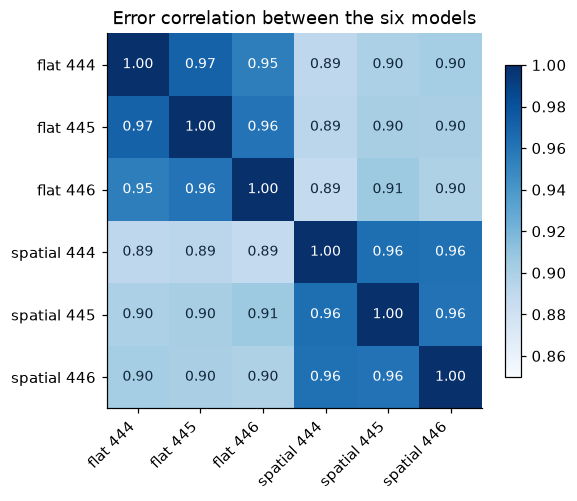

In [15]:
labels = [f"{'flat' if f == 'tcn' else 'spatial'} {s}" for f, s in keys]
fig, ax = plt.subplots(figsize=(5.5, 4.6))
im = ax.imshow(corr, cmap="Blues", vmin=.85, vmax=1)
ax.set_xticks(range(6), labels, rotation=45, ha="right"); ax.set_yticks(range(6), labels)
for a in range(6):
    for b in range(6):
        ax.text(b, a, f"{corr[a, b]:.2f}", ha="center", va="center", fontsize=9, color="white" if corr[a, b] > .95 else NAVY)
ax.set_title("Error correlation between the six models")
fig.colorbar(im, shrink=.8); plt.show()

✅ **Checkpoint 5:** `0.963` for seeds of the same architecture, `0.898` across architectures.

---

## Step 6 · Your turn: you can afford three trainings

1. Edit `my_pick` below: any 3 of `("tcn", 444)`, `("tcn", 445)`, `("tcn", 446)`, `("spatial_tcn", 444)`, `("spatial_tcn", 445)`, `("spatial_tcn", 446)`.
2. Run it, then run the check cell under it.
3. Try at least two picks, including one that mixes both architectures.
4. Write your answer in the last cell.

In [16]:
# ✏️ Edit this list: any 3 of the 6 models
my_pick = [("tcn", 444), ("tcn", 445), ("tcn", 446)]

my_ensemble = np.mean([preds[k] for k in my_pick], axis=0)
report("your ensemble", my_ensemble)

your ensemble            day 1 0.1522 | day 2 0.2824 | day 3 0.3868 | mean 0.2738


In [17]:
# ✅ Check your result (no need to edit)
import itertools

all3 = {c: score(np.mean([preds[k] for k in c], axis=0), y, mask) for c in itertools.combinations(keys, 3)}
mine = score(my_ensemble, y, mask)
mixed = len({f for f, _ in my_pick}) == 2

print(f"your score {mine:.4f}: rank {1 + sum(v < mine - 1e-9 for v in all3.values())} of {len(all3)}")
print("mixes both architectures:", "yes" if mixed else "no")
print(f"average of one-architecture picks: {np.mean([v for c, v in all3.items() if len({f for f, _ in c}) == 1]):.4f}")
print(f"average of mixed picks:            {np.mean([v for c, v in all3.items() if len({f for f, _ in c}) == 2]):.4f}")
print(f"best possible pick:                {min(all3.values()):.4f}")

your score 0.2738: rank 19 of 20
mixes both architectures: no
average of one-architecture picks: 0.2741
average of mixed picks:            0.2700
best possible pick:                0.2685


✅ **Reasonable result:** one architecture only ≈ `0.274`; mixing both `0.2685` to `0.2714`.

**Stretch:** use `np.median` instead of `np.mean`, or try a 2-model ensemble.

**Your answer** (double-click to edit): *What changed between your picks, and why? Hint: compare the ρ values from step 5.*